# Data Analyst Agent: walkthrough

This walks through the agent step by step, outside the Streamlit app:

1. Load a CSV with pandas.
2. Turn it into the **schema prompt** the LLM sees on every call.
3. Build the LangGraph agent: plan → generate → execute → (fix → execute)*.
4. Ask the spec's eight sample questions, plus a follow-up that builds on the previous answer.
5. Watch the self-correction loop repair broken code from a real traceback.

Run it as a script (`python deliverables/walkthrough.py`) or as the notebook `walkthrough.ipynb`,
which is built from this file. It needs an LLM key in `.env` (`GROQ_API_KEY` or `GOOGLE_API_KEY`).
Charts and a `walkthrough_results.json` summary go to `outputs/`; `generate_report.py` reads them.

In [1]:
import json
import sys
import time
from pathlib import Path

try:
    ROOT = Path(__file__).resolve().parent.parent
except NameError:  # in the notebook, which runs from deliverables/
    ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))

import pandas as pd
from langchain_core.language_models import BaseChatModel
from langchain_core.messages import AIMessage

from src.agent.graph import ask, build_graph
from src.agent.nodes import get_llm
from src.config import LLM_MODEL, LLM_NAME, MAX_RETRIES, SAMPLE_CSV
from src.data.loader import dataset_summary, format_schema_info, load_csv
from src.execution.sandbox import run_code

OUTPUTS = ROOT / "outputs"
OUTPUTS.mkdir(exist_ok=True)
IN_NOTEBOOK = "ipykernel" in sys.modules
PREVIEW_ROWS = 10  # rows of a table answer kept in the results file
if not IN_NOTEBOOK:  # model text can hold characters the Windows console encoding lacks
    sys.stdout.reconfigure(encoding="utf-8")

print(f"LLM: {LLM_NAME} · {LLM_MODEL}")

LLM: Groq · openai/gpt-oss-120b


## 1. Load the CSV

`load_csv` accepts a path or an uploaded file, falls back to latin-1 if UTF-8 fails, and turns
date-named columns into real datetimes, so the generated code can use `.dt` straight away.

In [2]:
df = load_csv(SAMPLE_CSV)
print(dataset_summary(df))
df.head()

{'rows': 1500, 'columns': 6, 'nulls': 20}


,date,product,region,revenue,quantity,salesperson
0,2023-01-01,Laptop,West,4624.51,5.0,Ben
1,2023-01-02,Mouse,South,60.80,2.0,Elena
2,2023-01-02,Laptop,South,4619.01,5.0,Dev
3,2023-01-03,Mouse,East,180.02,6.0,Farid
4,2023-01-03,Mouse,East,30.29,1.0,Carla


## 2. The schema prompt

The LLM never sees the whole dataset. It gets this summary instead: columns and types, row count,
a few sample rows, nulls, date ranges, category values and numeric stats. It is sent as the
system message of every call, so the model writes code against real column names.

In [3]:
schema_info = format_schema_info(df)
print(schema_info)

You are a data analyst agent. The user uploaded a CSV with this schema:

Columns: date (datetime64[us]), product (str), region (str), revenue (float64), quantity (float64), salesperson (str)
Row count: 1500
Sample (first 3 rows):
      date product region  revenue  quantity salesperson
2023-01-01  Laptop   West  4624.51       5.0         Ben
2023-01-02   Mouse  South    60.80       2.0       Elena
2023-01-02  Laptop  South  4619.01       5.0         Dev

Null counts: quantity: 8, salesperson: 12
Date ranges: date: 2023-01-01 to 2024-12-31
Text column values: product: Headset, Keyboard, Laptop, Monitor, Mouse; region: East, North, South, West; salesperson: Asha, Ben, Carla, Dev, Elena, Farid
Numeric stats:
       revenue  quantity
count  1500.00   1492.00
mean   1331.02      5.43
std    2015.92      2.84
min      27.04      1.00
25%     210.28      3.00
50%     460.48      5.00
75%    1424.13      8.00
max    9712.63     10.00



## 3. Build the agent

`build_graph()` compiles the LangGraph state machine. `ask()` runs one question through it and
returns the final state, including the `history` to pass to the next question for follow-ups.

In [4]:
graph = build_graph()
results = []  # one record per question, for the report


def on_retry(attempt, wait, exc):
    print(f"  ({LLM_NAME} is busy; retrying in {wait:.0f} s)")


def record(question, state, seconds, note=""):
    """Print one answer, save its chart, and keep a summary for the report."""
    kind, result = state["result_type"], state["result"]
    entry = {
        "question": question, "plan": state["plan"], "code": state["generated_code"],
        "result_type": kind, "retries": state["retries"], "error": state["error"],
        "seconds": round(seconds, 1), "note": note,
    }
    print(f"Q: {question}")
    print(f"Plan: {state['plan']}")
    print(f"Fix attempts: {state['retries']}  ·  {seconds:.1f} s")
    print("Code:\n" + state["generated_code"])
    if state["error"]:
        print("Failed after the last fix. Error:\n" + state["error"])
    elif kind == "dataframe":
        entry["columns"] = [str(col) for col in result.columns]
        entry["rows"] = json.loads(result.head(PREVIEW_ROWS).to_json(orient="values", date_format="iso"))
        entry["row_count"] = len(result)
        if not IN_NOTEBOOK:
            print(result.head(PREVIEW_ROWS).to_string())
    elif kind == "plotly":
        name = f"q{len(results) + 1:02d}"
        result.write_html(OUTPUTS / f"{name}.html", include_plotlyjs="cdn")
        result.write_image(OUTPUTS / f"{name}.png", width=900, height=500, scale=2)
        entry["chart"] = f"{name}.png"
        trace = result.data[0] if result.data else None
        # px.line draws "scatter" traces in lines mode
        entry["chart_type"] = "line" if trace and trace.type == "scatter" and "lines" in (trace.mode or "") else (
            trace.type if trace else None
        )
        print(f"Chart saved to outputs/{name}.png and .html")
    else:
        entry["value"] = result if isinstance(result, (int, float, str)) else str(result)
        print(f"Answer: {result}")
    results.append(entry)
    if IN_NOTEBOOK:  # show the real object under the cell
        from IPython.display import Image, display

        if kind == "dataframe":
            display(result.head(PREVIEW_ROWS))
        elif kind == "plotly":
            display(Image(filename=str(OUTPUTS / entry["chart"]), width=700))


def run(question, history=None, llm=None, note=""):
    start = time.perf_counter()
    state = ask(graph, df, schema_info, question, history, llm=llm, on_retry=on_retry)
    record(question, state, time.perf_counter() - start, note)
    return state

## 4. The spec's sample questions

Each answer is a table, a single value, text, or a Plotly chart. The agent picks the type from
the question; the code it wrote is printed under every answer.

In [5]:
state = run("Show the first 5 rows")

Q: Show the first 5 rows
Plan: I’ll use pandas to read the CSV and call `df.head(5)` to display the first five rows as a table (no filtering, grouping, or aggregation needed). The answer will be presented as a simple tabular view of those rows.
Fix attempts: 0  ·  2.2 s
Code:
RESULT = df.head(5)


,date,product,region,revenue,quantity,salesperson
0,2023-01-01,Laptop,West,4624.51,5.0,Ben
1,2023-01-02,Mouse,South,60.80,2.0,Elena
2,2023-01-02,Laptop,South,4619.01,5.0,Dev
3,2023-01-03,Mouse,East,180.02,6.0,Farid
4,2023-01-03,Mouse,East,30.29,1.0,Carla


In [6]:
state = run("What's the total revenue?")

Q: What's the total revenue?
Plan: I’ll load the CSV into a pandas DataFrame and compute the total revenue with a simple aggregation:

```python
total_revenue = df['revenue'].sum()
```

Since the question asks for a single overall total, I’ll return the resulting number as a single‑value answer.
Fix attempts: 0  ·  1.5 s
Code:
RESULT = round(df['revenue'].sum(), 2)
Answer: 1996526.43


Q: Revenue by region as a bar chart
Plan: I’ll group the data by **region**, sum the **revenue** for each region (ignoring any missing values), and then feed the resulting totals into Plotly Express’s `px.bar` to produce a bar chart of revenue by region. No filtering is needed beyond the aggregation step.
Fix attempts: 0  ·  1.8 s
Code:
region_rev = df.groupby('region', as_index=False)['revenue'].sum()
RESULT = px.bar(
    region_rev,
    x='region',
    y='revenue',
    title='Revenue by Region',
    labels={'region': 'Region', 'revenue': 'Total Revenue'}
)


Chart saved to outputs/q03.png and .html


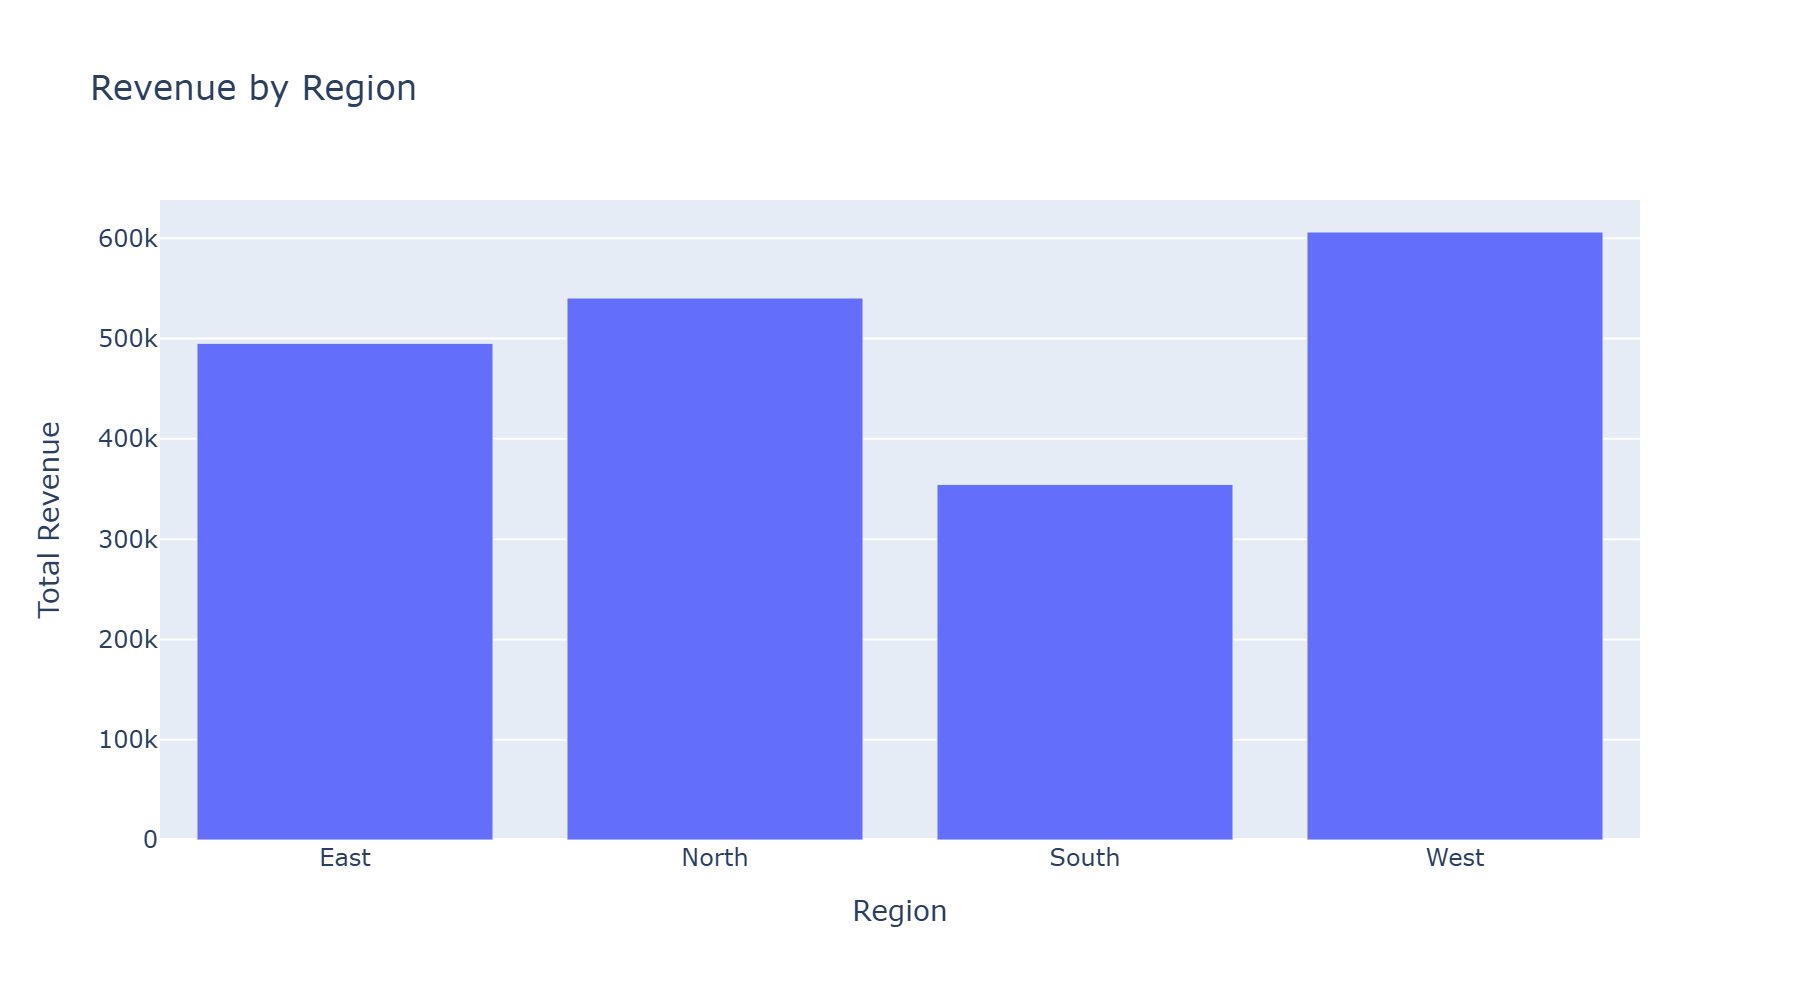

In [7]:
state = run("Revenue by region as a bar chart")

In [8]:
state = run("Top 3 salespersons by quantity sold")

Q: Top 3 salespersons by quantity sold
Plan: I’ll use the **salesperson** and **quantity** columns.  
1. Drop rows where *salesperson* or *quantity* is null.  
2. Group the data by *salesperson* and sum the *quantity* sold for each.  
3. Sort the summed quantities in descending order and keep the first three rows.  

The result will be presented as a **table** showing the three salespersons and their total quantities sold.
Fix attempts: 0  ·  1.7 s
Code:
# Drop rows with missing salesperson or quantity
clean_df = df.dropna(subset=["salesperson", "quantity"])

# Aggregate total quantity per salesperson
agg = clean_df.groupby("salesperson")["quantity"].sum().reset_index()

# Get top 3 salespersons by quantity sold
RESULT = agg.sort_values(by="quantity", ascending=False).head(3).reset_index(drop=True)


,salesperson,quantity
0,Ben,1497.0
1,Asha,1433.0
2,Farid,1310.0


Q: Monthly revenue trend
Plan: I will use the **date** column (converted to year‑month) and the **revenue** column.  
1. Convert `date` to a period like `date.dt.to_period('M')` (or format as “YYYY‑MM”).  
2. Group the data by that month period and aggregate `revenue` with `sum()`.  
3. Feed the resulting month‑wise totals to Plotly Express’s `px.line()` to produce a **line chart** showing the monthly revenue trend (x‑axis = month, y‑axis = total revenue).  

The answer will be presented as a line‑chart visualizing how revenue changes month‑by‑month.
Fix attempts: 0  ·  2.2 s
Code:
monthly_rev = (
    df.groupby(df["date"].dt.to_period("M").dt.to_timestamp())["revenue"]
    .sum()
    .reset_index()
    .rename(columns={"date": "month", "revenue": "total_revenue"})
)

RESULT = px.line(
    monthly_rev,
    x="month",
    y="total_revenue",
    title="Monthly Revenue Trend",
    labels={"month": "Month", "total_revenue": "Total Revenue"},
)


Chart saved to outputs/q05.png and .html


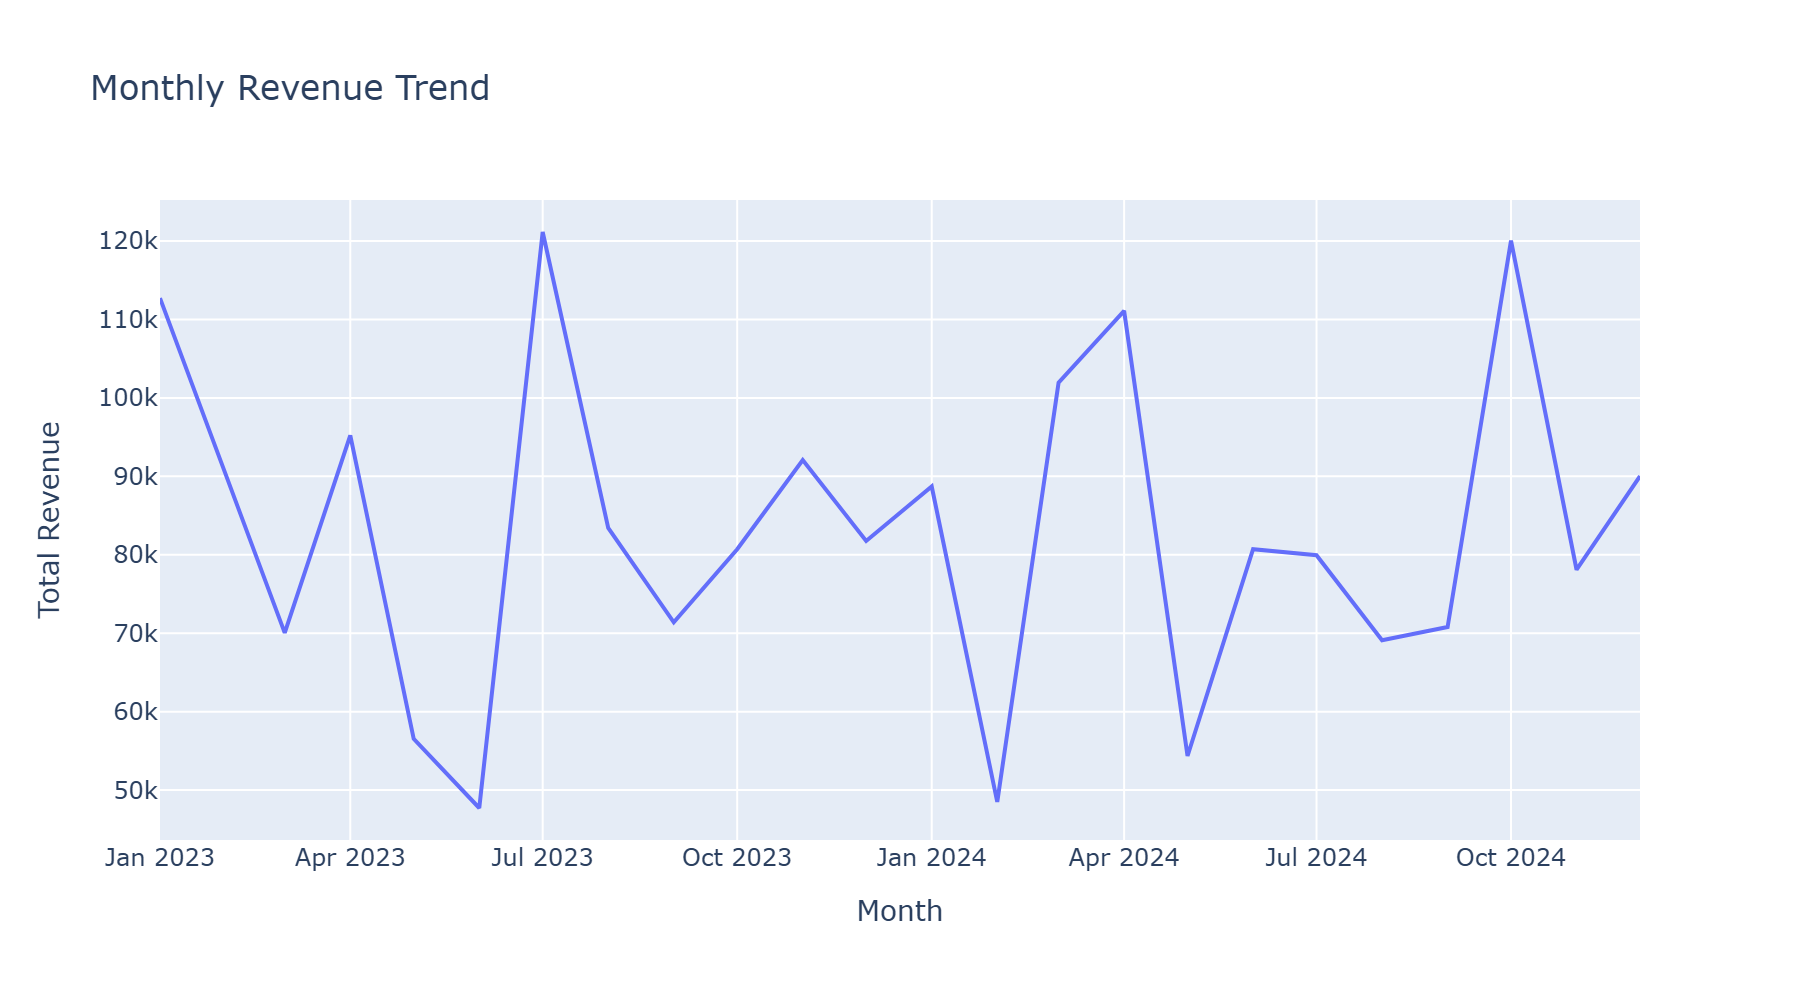

In [9]:
state = run("Monthly revenue trend")

## 5. A follow-up question

Passing the previous state's `history` lets the agent build on the code it just wrote.
"Now filter that to 2024 only" means the monthly trend above.

Q: Now filter that to 2024 only
Plan: I’ll filter the dataframe to rows where `df["date"].dt.year == 2024`, then reuse the same grouping‑by‑month logic on the `revenue` column (summing it for each month) and plot the result with Plotly Express `px.line`. The answer will be an updated line chart titled “2024 Monthly Revenue Trend”.
Fix attempts: 0  ·  2.6 s
Code:
df_2024 = df[df["date"].dt.year == 2024]

monthly_rev = (
    df_2024.groupby(df_2024["date"].dt.to_period("M").dt.to_timestamp())["revenue"]
    .sum()
    .reset_index()
    .rename(columns={"date": "month", "revenue": "total_revenue"})
)

RESULT = px.line(
    monthly_rev,
    x="month",
    y="total_revenue",
    title="2024 Monthly Revenue Trend",
    labels={"month": "Month", "total_revenue": "Total Revenue"},
)


Chart saved to outputs/q06.png and .html


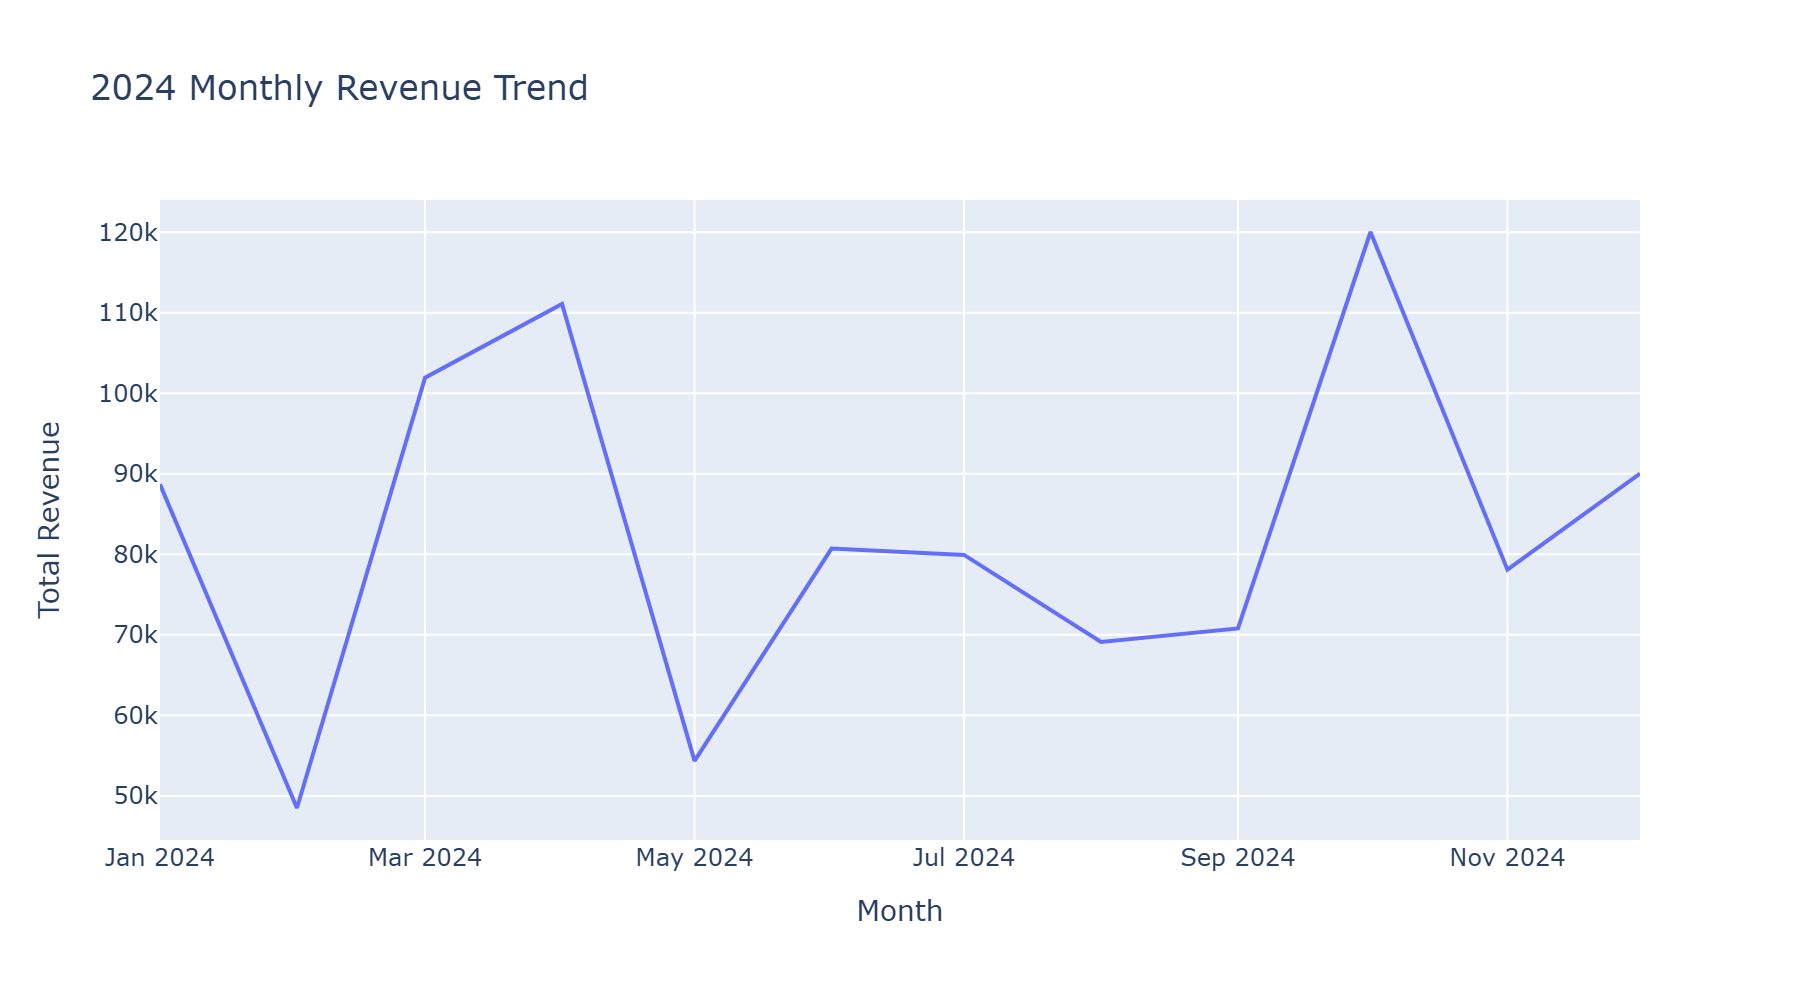

In [10]:
state = run("Now filter that to 2024 only", history=state["history"], note="follow-up to the monthly trend")

In [11]:
state = run("Which product has the highest average revenue?")

  (Groq is busy; retrying in 2 s)


  (Groq is busy; retrying in 4 s)


Q: Which product has the highest average revenue?
Plan: I’ll load the CSV into a pandas DataFrame, then:

1. **Select columns** – use **`product`** and **`revenue`**.  
2. **Group & aggregate** – `df.groupby('product')['revenue'].mean()` to compute the average revenue for each product.  
3. **Identify the maximum** – pick the product with the highest mean value (e.g., using `.idxmax()`).

The answer will be a short sentence naming the product that has the highest average revenue (e.g., “Laptop has the highest average revenue”). No chart or table is needed.
Fix attempts: 0  ·  8.1 s
Code:
avg_rev = df.groupby('product')['revenue'].mean()
max_product = avg_rev.idxmax()
max_value = avg_rev.max()
RESULT = f"{max_product} has the highest average revenue ({max_value:,.2f})."
Answer: Laptop has the highest average revenue (5,031.41).


  (Groq is busy; retrying in 6 s)


Q: Compare regions with a pie chart
Plan: I’ll aggregate the data by `region`, summing the `revenue` column (ignoring any missing values), and then feed the resulting region‑revenue series to Plotly Express’s `px.pie` to produce a pie chart that shows each region’s share of total revenue. No filtering beyond dropping the few null rows is needed.
Fix attempts: 0  ·  8.3 s
Code:
region_rev = df.groupby('region', as_index=False)['revenue'].sum()
RESULT = px.pie(
    region_rev,
    names='region',
    values='revenue',
    title='Revenue Share by Region',
    labels={'region': 'Region', 'revenue': 'Revenue'}
)


Chart saved to outputs/q08.png and .html


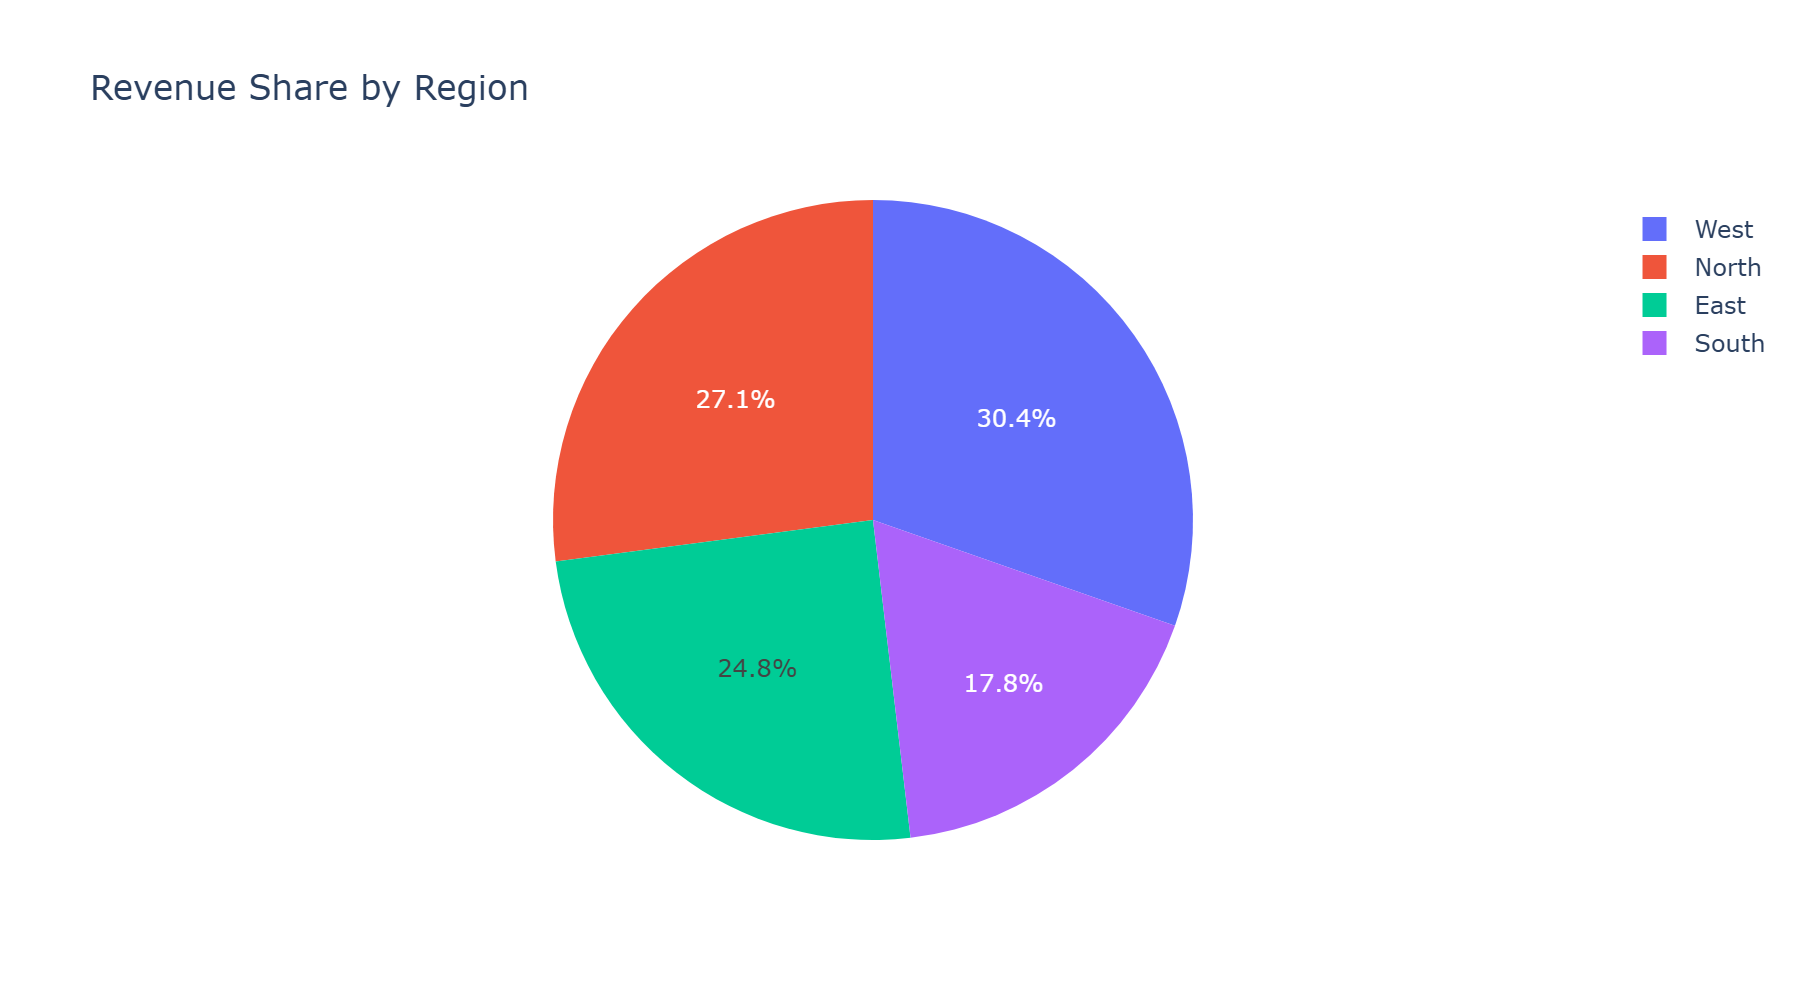

In [12]:
state = run("Compare regions with a pie chart")

  (Groq is busy; retrying in 4 s)


  (Groq is busy; retrying in 4 s)


Q: Show a heatmap of revenue by product and region
Plan: I’ll aggregate the data with pandas by grouping on **product** and **region**, summing the **revenue** for each combination (ignoring the few missing values), and then feed that pivot‑table into Plotly Express’s `px.imshow` (or `px.density_heatmap`) to produce a heatmap chart of revenue by product × region. The answer will be a heatmap figure.
Fix attempts: 0  ·  9.9 s
Code:
pivot = (
    df.groupby(["product", "region"], as_index=False)["revenue"]
    .sum()
    .pivot(index="product", columns="region", values="revenue")
)

RESULT = px.imshow(
    pivot,
    labels=dict(x="Region", y="Product", color="Revenue"),
    title="Revenue Heatmap by Product and Region",
)


Chart saved to outputs/q09.png and .html


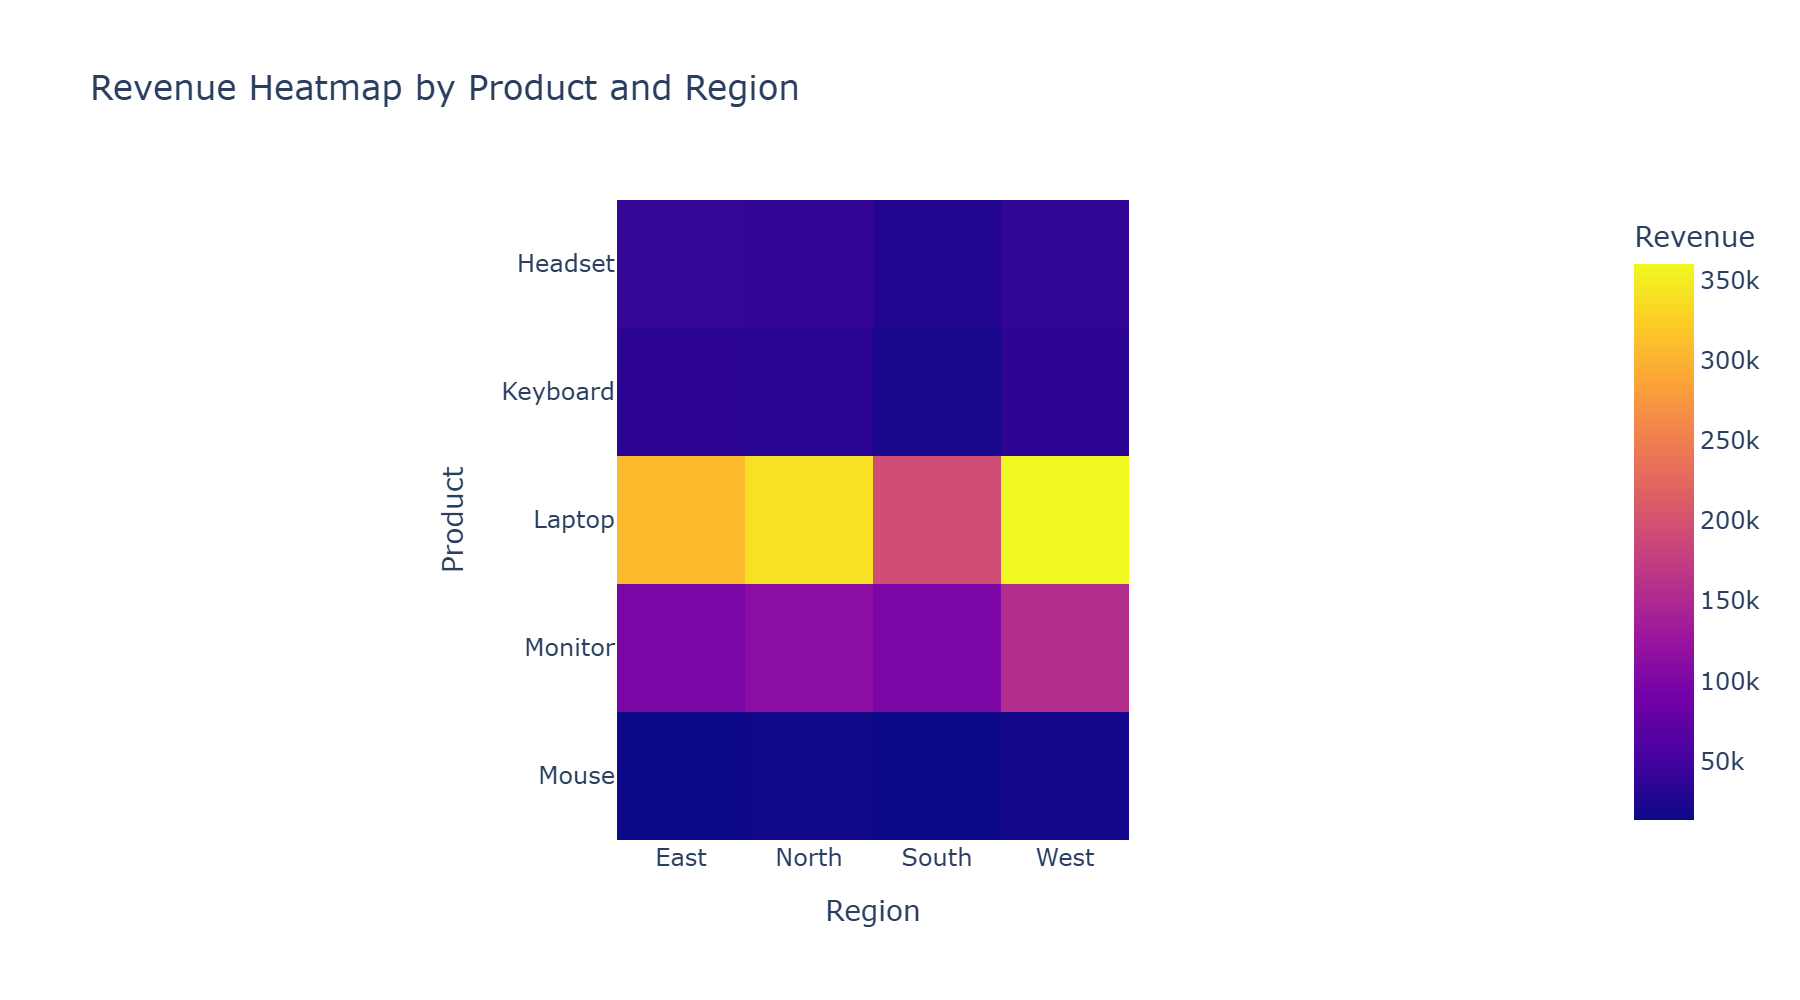

In [13]:
state = run("Show a heatmap of revenue by product and region")

## 6. Self-correction

Today's models rarely fail on this clean data, so the loop is hard to see. To show it, the
wrapper below replaces the model's **first** code with a version that uses a misspelled column.
Everything after that is real: the sandbox raises a genuine `KeyError`, and the live model's
fix node reads the traceback and repairs the code.

In [14]:
class FirstCodeBroken:
    """Passes calls to the real model, except the first code-writing call (right after the plan)."""

    BROKEN = "RESULT = df.groupby('product')['revenu'].sum().sort_values(ascending=False)"

    def __init__(self, llm: BaseChatModel):
        self.llm, self.answered, self.broke = llm, 0, False

    def invoke(self, messages):
        if self.answered == 1 and not self.broke:  # count answers, not attempts: a 429 is retried
            self.broke = True
            return AIMessage(content=self.BROKEN)
        reply = self.llm.invoke(messages)
        self.answered += 1
        return reply


question = "Total revenue by product, highest first"
start = time.perf_counter()
state = ask(graph, df, schema_info, question, llm=FirstCodeBroken(get_llm()), on_retry=on_retry)
seconds = time.perf_counter() - start
# the first error is gone from the final state, so rebuild it the way the sandbox reported it
first_error = run_code(FirstCodeBroken.BROKEN, df)["error"]
print("First attempt:\n" + FirstCodeBroken.BROKEN + "\n\nSandbox error:\n" + first_error)
record(question, state, seconds, note="self-correction demo: first code broken on purpose")
results[-1].update({"broken_code": FirstCodeBroken.BROKEN, "first_error": first_error})
assert state["retries"] >= 1 and not state["error"], "the fix node should have repaired the code"

  (Groq is busy; retrying in 3 s)


First attempt:
RESULT = df.groupby('product')['revenu'].sum().sort_values(ascending=False)

Sandbox error:
Traceback (most recent call last):
  File "<generated code>", line 1, in <module>
    RESULT = df.groupby('product')['revenu'].sum().sort_values(ascending=False)
             ~~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^
  File "pandas/core/base.py", line 241, in __getitem__
    raise KeyError(f"Column not found: {key}")
KeyError: 'Column not found: revenu'
Q: Total revenue by product, highest first
Plan: I’ll group the DataFrame by **product**, sum the **revenue** column for each group, sort the results in descending order, and then display the ordered totals as a table (or as a horizontal bar chart with Plotly Express if a visual is requested). No filtering is needed beyond handling the few missing values, which pandas will ignore when summing.
Fix attempts: 1  ·  5.7 s
Code:
RESULT = df.groupby('product')['revenue'].sum().sort_values(ascending=False).reset_index()


,product,revenue
0,Laptop,1202506.99
1,Monitor,467745.69
2,Headset,143747.43
3,Keyboard,122904.31
4,Mouse,59622.01


## 7. Save the results

`generate_report.py` builds `Project_Report.pdf` from this file and the chart PNGs.

In [15]:
summary = {
    "provider": LLM_NAME, "model": LLM_MODEL, "max_retries": MAX_RETRIES,
    "dataset": {"file": SAMPLE_CSV.name, **dataset_summary(df)},
    "run_at": time.strftime("%Y-%m-%d %H:%M"),
    "results": results,
}
(OUTPUTS / "walkthrough_results.json").write_text(json.dumps(summary, indent=2, default=str), encoding="utf-8")
ok = sum(1 for r in results if not r["error"])
print(f"{ok} of {len(results)} questions answered; saved outputs/walkthrough_results.json")

10 of 10 questions answered; saved outputs/walkthrough_results.json
